In [1]:
import pandas as pd

train_df = pd.read_csv("../data/raw/banking77/train.csv")
test_df = pd.read_csv("../data/raw/banking77/test.csv")

print("Train:", train_df.shape)
print("Test :", test_df.shape)

Train: (10003, 2)
Test : (3080, 2)


In [2]:
X_train = train_df["text"]
y_train = train_df["category"]

X_test = test_df["text"]
y_test = test_df["category"]

In [3]:
X_train = train_df["text"]
y_train = train_df["category"]

X_test = test_df["text"]
y_test = test_df["category"]

In [4]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (10003,)
y_train: (10003,)
X_test: (3080,)
y_test: (3080,)


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [6]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2
)

In [7]:
X_train_tfidf = vectorizer.fit_transform(X_train)

In [8]:
X_test_tfidf = vectorizer.transform(X_test)

In [9]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (10003, 10292)
Testing TF-IDF shape: (3080, 10292)


In [10]:
print("Vocabulary size:", len(vectorizer.vocabulary_))

Vocabulary size: 10292


In [11]:
X_train_tfidf[0]

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 11 stored elements and shape (1, 10292)>

In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed.")

Model training completed.


In [13]:
y_pred = model.predict(X_test_tfidf)

print("Predictions generated:", len(y_pred))

Predictions generated: 3080


In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8578


In [15]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred
)

print(report)

                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.88      0.95      0.92        40
                                activate_my_card       1.00      0.95      0.97        40
                                       age_limit       1.00      1.00      1.00        40
                         apple_pay_or_google_pay       0.98      1.00      0.99        40
                                     atm_support       0.86      0.80      0.83        40
                                automatic_top_up       1.00      0.90      0.95        40
         balance_not_updated_after_bank_transfer       0.65      0.78      0.70        40
balance_not_updated_after_cheque_or_cash_deposit       0.84      0.93      0.88        40
                         beneficiary_not_allowed       0.90      0.88      0.89        40
                                 cancel_transfer       0.88      0.95      0.92        40
         

In [16]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.88      0.95      0.92        40
                                activate_my_card       1.00      0.95      0.97        40
                                       age_limit       1.00      1.00      1.00        40
                         apple_pay_or_google_pay       0.98      1.00      0.99        40
                                     atm_support       0.86      0.80      0.83        40
                                automatic_top_up       1.00      0.90      0.95        40
         balance_not_updated_after_bank_transfer       0.65      0.78      0.70        40
balance_not_updated_after_cheque_or_cash_deposit       0.84      0.93      0.88        40
                         beneficiary_not_allowed       0.90      0.88      0.89        40
                                 cancel_transfer       0.88      0.95      0.92        40
         

In [17]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion matrix shape:", cm.shape)

Confusion matrix shape: (77, 77)


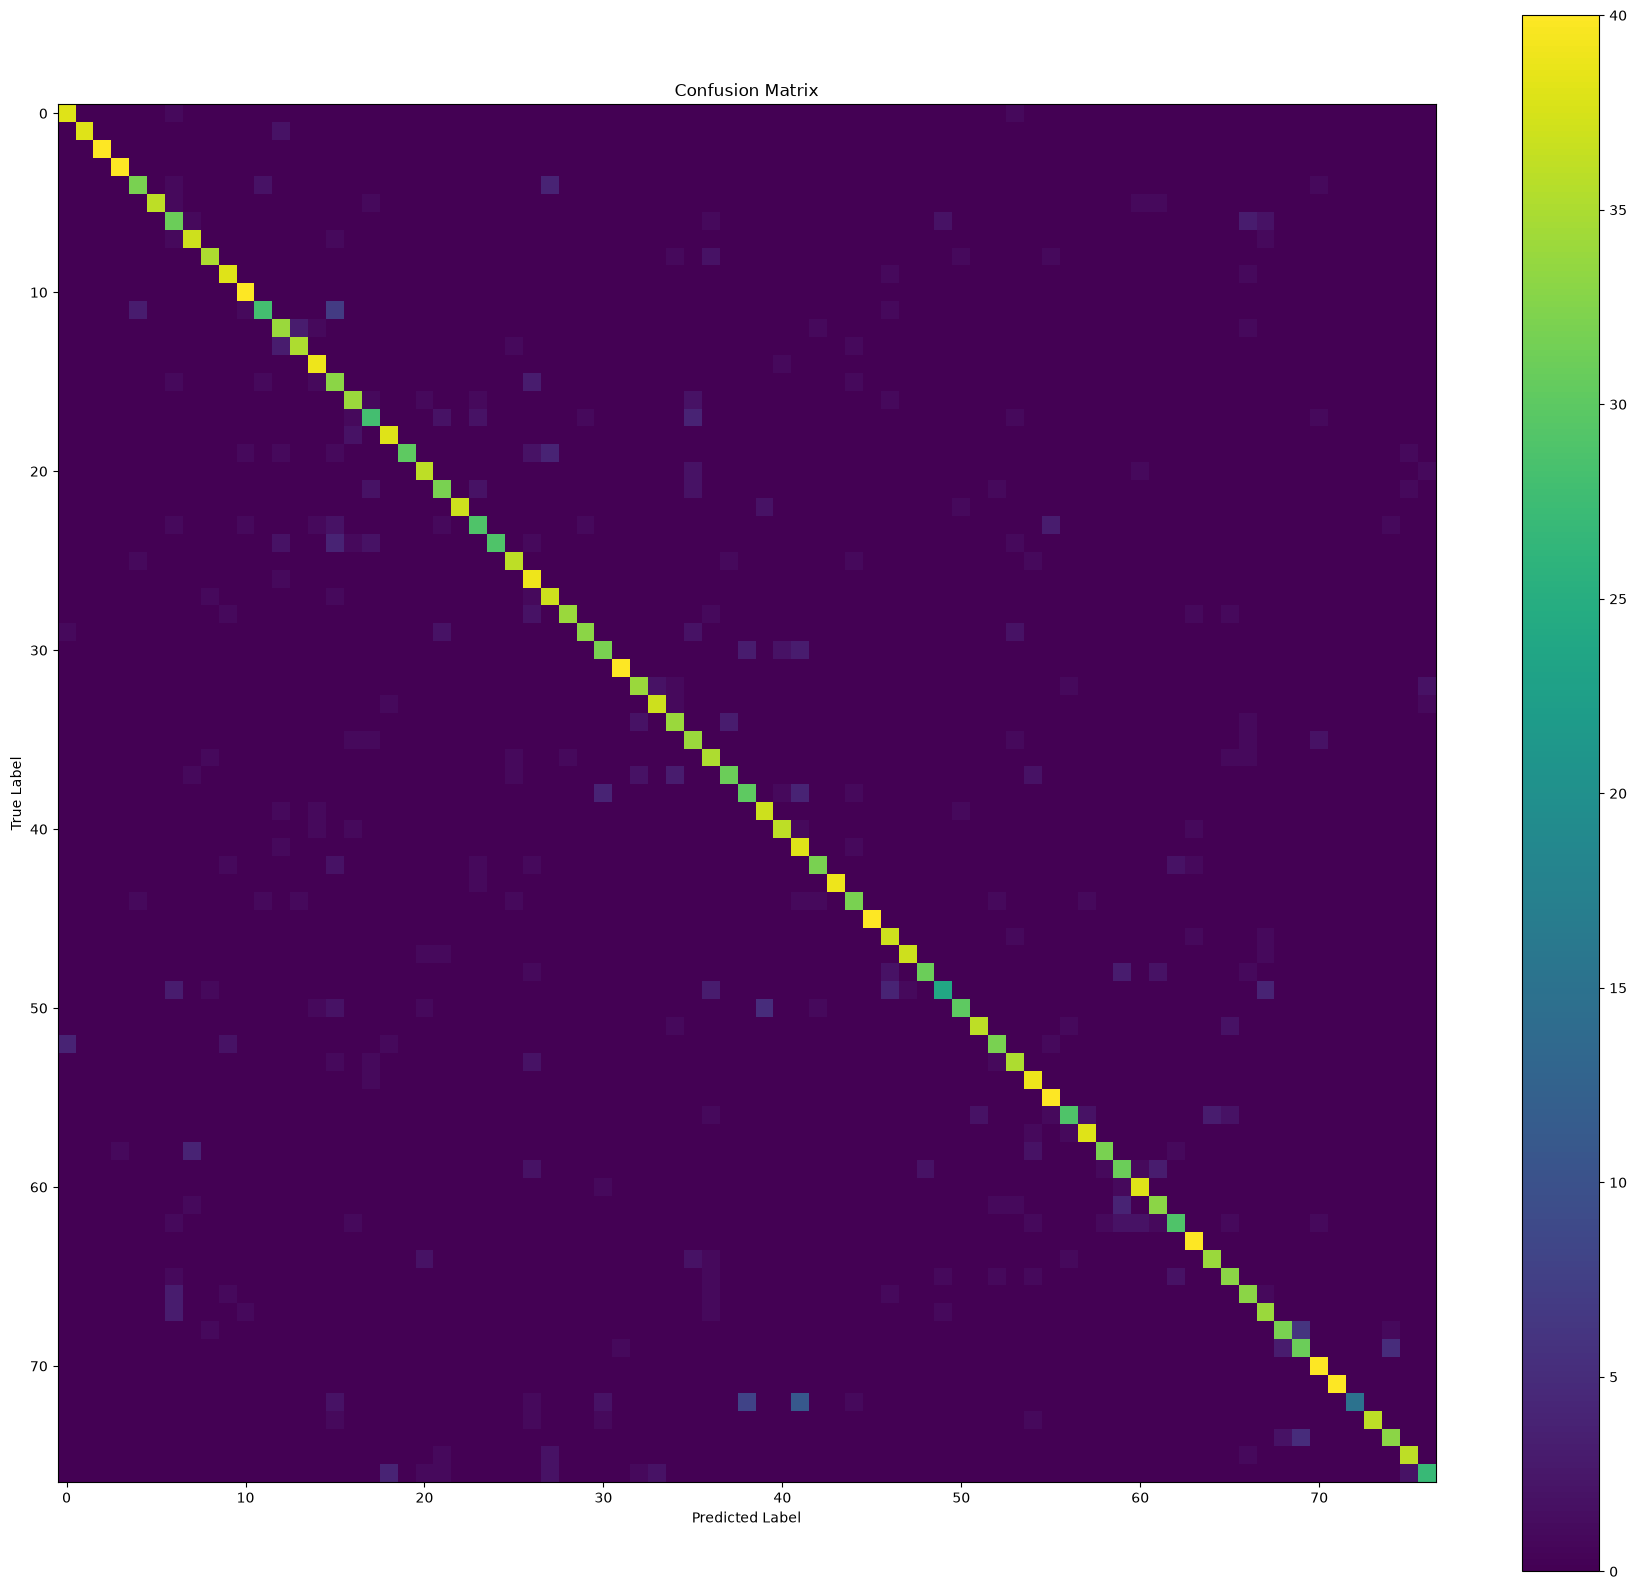

In [18]:
plt.figure(figsize=(18, 16))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.colorbar()

plt.tight_layout()
plt.show()

In [19]:
import pandas as pd

results_df = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred
})

wrong_df = results_df[results_df["actual"] != results_df["predicted"]]

wrong_by_label = (
    wrong_df
    .groupby("actual")
    .size()
    .reset_index(name="wrong_predictions")
    .sort_values("wrong_predictions", ascending=False)
)

print(wrong_by_label.to_string(index=False))

                                          actual  wrong_predictions
                        virtual_card_not_working                 25
                                pending_transfer                 16
         wrong_exchange_rate_for_cash_withdrawal                 13
                                 card_acceptance                 12
                     card_payment_not_recognised                 12
                  top_up_by_bank_transfer_charge                 11
                         contactless_not_working                 11
                                compromised_card                 11
                              topping_up_by_card                 11
                                  card_swallowed                 10
                                     pin_blocked                 10
                     get_disposable_virtual_card                 10
                              verify_my_identity                  9
                                   top_up_failed

In [20]:
confused_pairs = (
    wrong_df
    .groupby(["actual", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print(confused_pairs.head(20).to_string(index=False))

                                 actual                                        predicted  count
               virtual_card_not_working                             getting_virtual_card     11
               virtual_card_not_working                      get_disposable_virtual_card      8
                        card_acceptance                                 card_not_working      7
              unable_to_verify_identity                               verify_my_identity      6
                     verify_my_identity                              why_verify_identity      5
                            pin_blocked                                get_physical_card      5
                    why_verify_identity                               verify_my_identity      5
                        top_up_reverted                                    top_up_failed      4
            card_payment_not_recognised                        extra_charge_on_statement      4
               top_up_by_cash_or_cheque 